In [1]:
# the purpose of this notebook is to visualize Negars formulas + 95% confidence intervals
# as well as the formulas the model recommended

In [2]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]
measured_se_cols = [
    "Avg_Density SE",
    "Dry Strength SE",
    "Wet Strength SE",
]

# Keep each target beside its standard error column
measured_cols = [
    col
    for target, se in zip(measured_target_cols, measured_se_cols)
    for col in (target, se)
]
df = df.loc[:, formula_cols + measured_cols]

df["std_Avg_Density_g_cm3"] = df["Avg_Density SE"] * np.sqrt(3)
df["std_Dry Strength Mean"] = df["Dry Strength SE"] * np.sqrt(3)
df["std_Wet Strength Mean"] = df["Wet Strength SE"] * np.sqrt(3)

print(df.head())

   TEM  Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0    8      NaN    NaN     NaN   NaN           0.192000        0.002667   
1    8      0.7    NaN     NaN   NaN           0.195000        0.007263   
2    8      1.0    NaN     NaN   NaN           0.159000        0.005033   
3    8      1.5    NaN     NaN   NaN           0.159933        0.004410   
4    8      2.0    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g_cm3  std_Dry Strength Mean  std_Wet Strength Mean  
0            

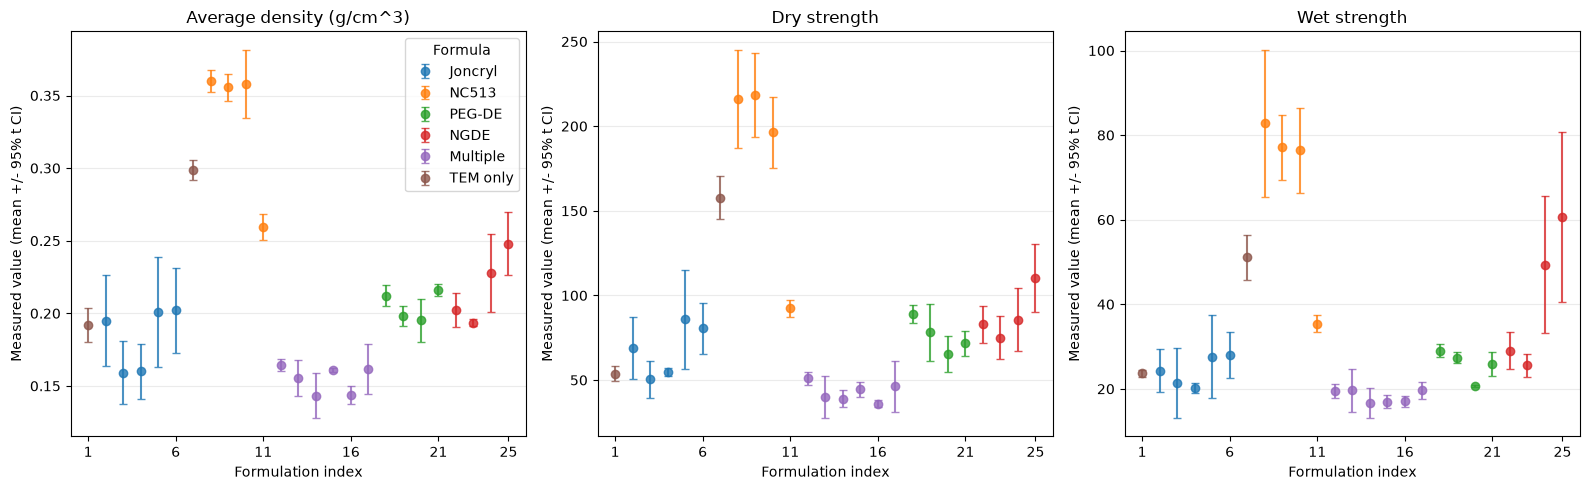

In [3]:
# Plot each formulation's measured mean and 95 CI, colored by formula.
import matplotlib.pyplot as plt
import numpy as np

target_se_pairs = {
    "Avg_Density_g_cm3": "Avg_Density SE",
    "Dry Strength Mean": "Dry Strength SE",
    "Wet Strength Mean": "Wet Strength SE",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "Dry Strength Mean": "Dry strength",
    "Wet Strength Mean": "Wet strength",
}
ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"
single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = ingredient_presence.loc[single_ingredient].idxmax(axis=1)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))

fig, axes = plt.subplots(1, len(target_se_pairs), figsize=(16, 5), sharex=True)

for ax, target in zip(axes, target_se_pairs):
    se_col = target_se_pairs[target]
    plot_data = df[[target, se_col, "formula_group"]].dropna(
        subset=[target, se_col]
    )

    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        means = group_data[target].to_numpy()
        standard_errors = group_data[se_col].to_numpy()
        n = 3
        degrees_of_freedom = n - 1
        t_critical_95 = 4.302652729911275  # t_(0.975, df=2)
        ci_95_half_width = t_critical_95 * standard_errors
        formulation_indices = group_data.index.to_numpy() + 1

        ax.errorbar(
            formulation_indices,
            means,
            yerr=ci_95_half_width,
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    ax.set_title(target_labels[target])
    ax.set_xlabel("Formulation index")
    ax.set_ylabel("Measured value (mean +/- 95% t CI)")
    ax.set_xlim(0, len(df) + 1)
    ax.set_xticks(np.unique(np.append(np.arange(1, len(df) + 1, 5), len(df))))
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(title="Formula")
fig.tight_layout()
plt.show()

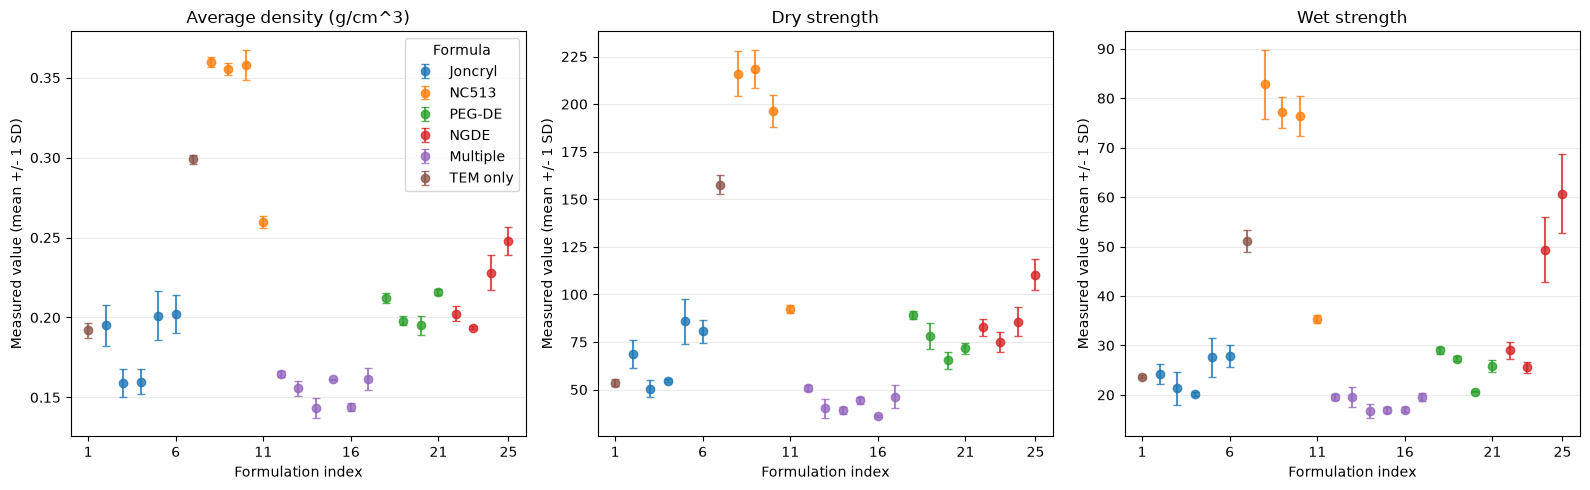

In [4]:
# Plot each formulation's measured mean +/- 1 standard deviation, colored by formula.
import matplotlib.pyplot as plt
import numpy as np

target_std_pairs = {
    "Avg_Density_g_cm3": "std_Avg_Density_g_cm3",
    "Dry Strength Mean": "std_Dry Strength Mean",
    "Wet Strength Mean": "std_Wet Strength Mean",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "Dry Strength Mean": "Dry strength",
    "Wet Strength Mean": "Wet strength",
}

ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"

single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = (
    ingredient_presence.loc[single_ingredient].idxmax(axis=1)
)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))

fig, axes = plt.subplots(1, len(target_std_pairs), figsize=(16, 5), sharex=True)

for ax, target in zip(axes, target_std_pairs):
    std_col = target_std_pairs[target]
    plot_data = df[[target, std_col, "formula_group"]].dropna(
        subset=[target, std_col]
    )

    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        means = group_data[target].to_numpy()
        standard_deviations = group_data[std_col].to_numpy()
        formulation_indices = group_data.index.to_numpy() + 1

        ax.errorbar(
            formulation_indices,
            means,
            yerr=standard_deviations,
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    ax.set_title(target_labels[target])
    ax.set_xlabel("Formulation index")
    ax.set_ylabel("Measured value (mean +/- 1 SD)")
    ax.set_xlim(0, len(df) + 1)
    ax.set_xticks(np.unique(np.append(np.arange(1, len(df) + 1, 5), len(df))))
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(title="Formula")
fig.tight_layout()
plt.show()

In [5]:
# generate candidate formulas, they are stored in candidate_set

# Formula constraints:
# - TEM: 5-8%.
# - Each chain extender (Joncryl, NC513, PEG-DE, NGDE): 0.7-3% when included; 0% when omitted.
# - Combined chain extender amount: no more than 6%.
# - Generate 100,000 valid candidate formulas.
import numpy as np
import pandas as pd

candidate_count = 100_000
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(10_000, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]
    extender_amounts = rng.uniform(0.7, 3.0, size=(batch_size, len(chain_extender_cols)))
    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 6.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(5.0, 8.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(5.0, 8.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(6.0).all()
for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    assert candidate_set.loc[active, col].between(0.7, 3.0).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 100,000 valid candidate formulas.
        TEM   Joncryl     NC513    PEG-DE      NGDE
0  7.498286  0.000000  0.000000  2.198651  0.000000
1  6.711942  1.784903  0.787018  1.213481  0.724965
2  5.505915  0.850501  1.969780  2.903304  0.000000
3  5.838431  2.472247  0.000000  1.159775  0.000000
4  5.735430  2.128875  0.000000  0.000000  0.791036
Maximum total chain extender: 5.999979539311976


In [6]:
# load the gpr_models
import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")

# get predictions for these formulas from the GPR models

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
X_candidates = candidate_set.loc[:, feature_cols]

batch_size = 5_000
prediction_columns = {}

for name, model in gpr_models.items():
    batches = [
        model.predict(X_candidates.iloc[start : start + batch_size])
        for start in range(0, len(X_candidates), batch_size)
    ]
    prediction_columns[f"pred_{name}"] = np.concatenate(batches)

predictions = pd.DataFrame(prediction_columns, index=candidate_set.index)
candidate_predictions = pd.concat([candidate_set, predictions], axis=1)

display(candidate_predictions.head())


,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,pred_Dry Strength Mean,pred_Wet Strength Mean
0,7.498286,0.000000,0.000000,2.198651,0.000000,0.211892,87.620140,33.79809
1,6.711942,1.784903,0.787018,1.213481,0.724965,0.214483,87.620447,33.79809
2,5.505915,0.850501,1.969780,2.903304,0.000000,0.232021,87.622346,33.79809
3,5.838431,2.472247,0.000000,1.159775,0.000000,0.215118,87.620447,33.79809
4,5.735430,2.128875,0.000000,0.000000,0.791036,0.215942,87.620450,33.79809


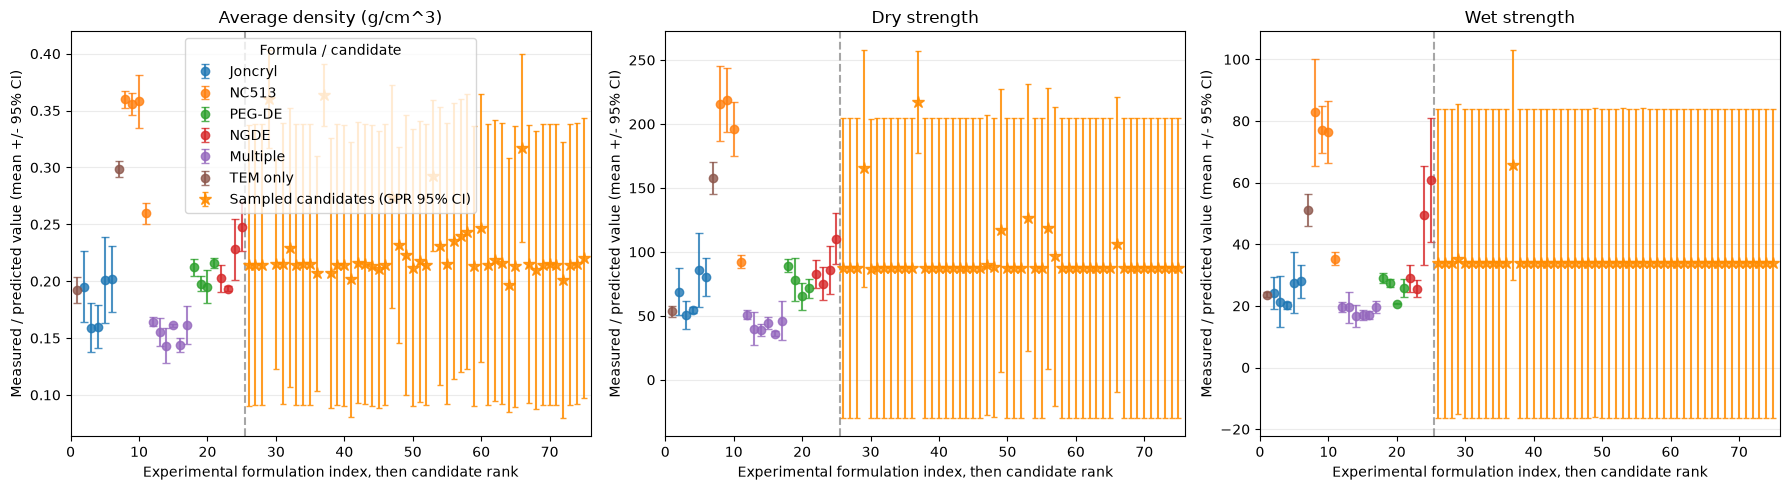

In [7]:
# sample 50 random candidate formulas and put on the plot above to visualize

import numpy as np
import matplotlib.pyplot as plt

# Reproducible random sample of 50 candidate formulas
sampled_candidates = candidate_predictions.sample(n=50, random_state=42)
X_sample = sampled_candidates[formula_cols]

target_se_pairs = {
    "Avg_Density_g_cm3": "Avg_Density SE",
    "Dry Strength Mean": "Dry Strength SE",
    "Wet Strength Mean": "Wet Strength SE",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "Dry Strength Mean": "Dry strength",
    "Wet Strength Mean": "Wet strength",
}

# Get each model's predictions and uncertainty for the sampled candidates
candidate_stats = {}
for target in target_se_pairs:
    mean, std = gpr_models[target].predict(X_sample, return_std=True)
    candidate_stats[target] = (mean, std)

# Group experimental formulas by their ingredients, as in your existing plot
ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"

single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = (
    ingredient_presence.loc[single_ingredient].idxmax(axis=1)
)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))

# Put candidates after the experimental formulation indices
candidate_x = len(df) + np.arange(1, len(sampled_candidates) + 1)

fig, axes = plt.subplots(1, len(target_se_pairs), figsize=(18, 5), sharex=True)

for ax, target in zip(axes, target_se_pairs):
    se_col = target_se_pairs[target]
    plot_data = df[[target, se_col, "formula_group"]].dropna(
        subset=[target, se_col]
    )

    # Experimental measurements with 95% t-confidence intervals
    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        means = group_data[target].to_numpy()
        standard_errors = group_data[se_col].to_numpy()
        ci_95_half_width = 4.302652729911275 * standard_errors  # t CI, n=3
        formulation_indices = group_data.index.to_numpy() + 1

        ax.errorbar(
            formulation_indices,
            means,
            yerr=ci_95_half_width,
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    # Candidate predictions with approximate 95% GPR intervals
    candidate_mean, candidate_std = candidate_stats[target]
    ax.errorbar(
        candidate_x,
        candidate_mean,
        yerr=1.96 * candidate_std,
        fmt="*",
        markersize=9,
        capsize=2,
        color="darkorange",
        ecolor="darkorange",
        alpha=0.85,
        label="Sampled candidates (GPR 95% CI)",
    )

    ax.axvline(len(df) + 0.5, color="gray", linestyle="--", alpha=0.7)
    ax.set_title(target_labels[target])
    ax.set_xlabel("Experimental formulation index, then candidate rank")
    ax.set_ylabel("Measured / predicted value (mean +/- 95% CI)")
    ax.set_xlim(0, len(df) + len(sampled_candidates) + 1)
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(title="Formula / candidate")
fig.tight_layout()
plt.show()

Selected 50 candidates with the lowest average relative uncertainty.


,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,pred_Dry Strength Mean,pred_Wet Strength Mean
72183,7.999739,0.000000,0.0,1.469144,0.000000,0.202104,71.466753,23.671191
23282,7.999596,0.924735,0.0,0.000000,0.000000,0.166116,54.129051,23.675686
61794,7.999279,0.000000,0.0,2.852876,0.000000,0.204846,71.466730,23.682928
64943,7.998777,0.000000,0.0,1.055038,0.000000,0.201304,71.471738,23.712719
60772,7.999982,0.000000,0.0,0.000000,0.733268,0.201871,77.923324,27.055086


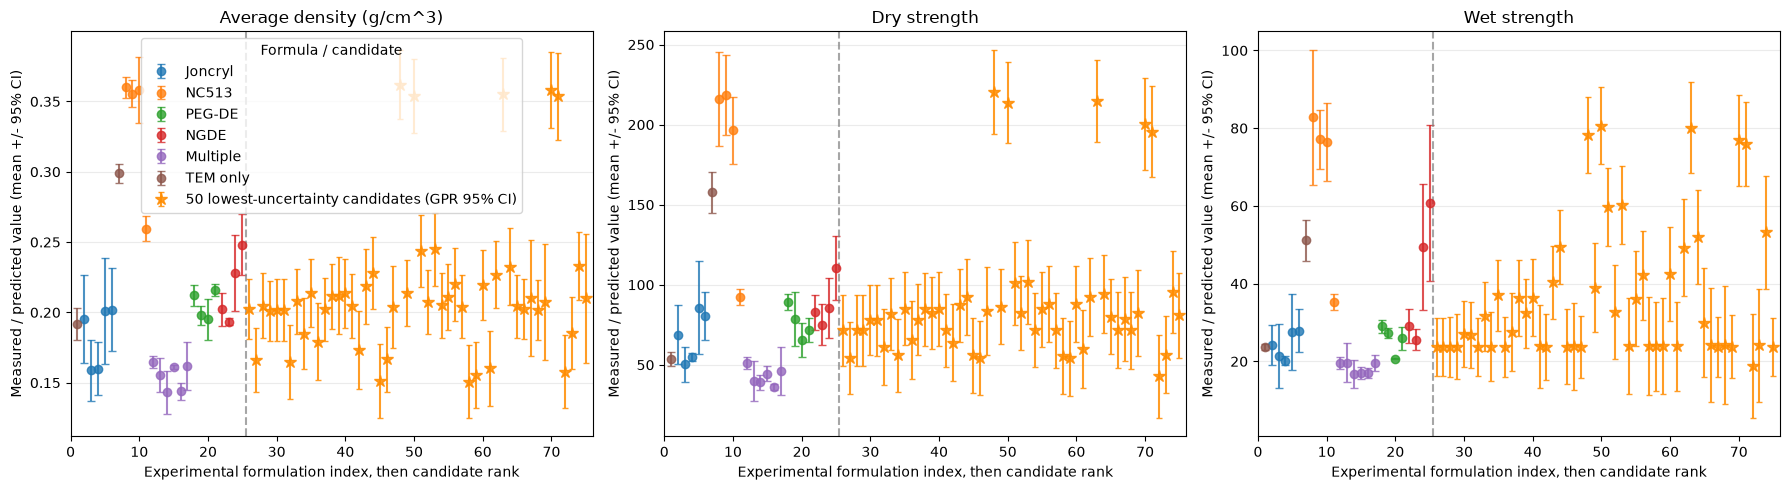

In [8]:
# now out of the 100,000 candidate formulas, pick the 50 lowest uncertainty formulas and give me the same graphs again

import numpy as np
import matplotlib.pyplot as plt

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

target_se_pairs = {
    "Avg_Density_g_cm3": "Avg_Density SE",
    "Dry Strength Mean": "Dry Strength SE",
    "Wet Strength Mean": "Wet Strength SE",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "Dry Strength Mean": "Dry strength",
    "Wet Strength Mean": "Wet strength",
}

# Get each model's predicted mean and standard deviation for every candidate.
X_candidates = candidate_predictions.loc[:, formula_cols]
batch_size = 5_000
candidate_stats = {}

for target in target_se_pairs:
    mean_batches = []
    std_batches = []

    for start in range(0, len(X_candidates), batch_size):
        mean_batch, std_batch = gpr_models[target].predict(
            X_candidates.iloc[start : start + batch_size],
            return_std=True,
        )
        mean_batches.append(mean_batch)
        std_batches.append(std_batch)

    candidate_stats[target] = (
        np.concatenate(mean_batches),
        np.concatenate(std_batches),
    )

# Rank candidates using the average uncertainty relative to each target's
# experimental standard deviation, so the different measurement scales are comparable.
relative_uncertainty = pd.DataFrame(index=candidate_predictions.index)

for target in target_se_pairs:
    experimental_sd = df[target].std()
    relative_uncertainty[target] = candidate_stats[target][1] / experimental_sd

uncertainty_score = relative_uncertainty.mean(axis=1)
selected_positions = np.argsort(uncertainty_score.to_numpy())[:50]
selected_candidates = candidate_predictions.iloc[selected_positions]

print("Selected 50 candidates with the lowest average relative uncertainty.")
display(selected_candidates.head())

# Group the experimental formulas by ingredient composition.
ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"

single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = (
    ingredient_presence.loc[single_ingredient].idxmax(axis=1)
)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))

# Place the candidate points after the experimental formulation indices.
candidate_x = len(df) + np.arange(1, len(selected_positions) + 1)

fig, axes = plt.subplots(1, len(target_se_pairs), figsize=(18, 5), sharex=True)

for ax, target in zip(axes, target_se_pairs):
    se_col = target_se_pairs[target]
    plot_data = df[[target, se_col, "formula_group"]].dropna(
        subset=[target, se_col]
    )

    # Experimental measurements and their 95% t-confidence intervals (n=3).
    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        means = group_data[target].to_numpy()
        standard_errors = group_data[se_col].to_numpy()
        ci_95_half_width = 4.302652729911275 * standard_errors

        ax.errorbar(
            group_data.index.to_numpy() + 1,
            means,
            yerr=ci_95_half_width,
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    # Selected candidates and their approximate 95% GPR intervals.
    candidate_mean, candidate_std = candidate_stats[target]
    ax.errorbar(
        candidate_x,
        candidate_mean[selected_positions],
        yerr=1.96 * candidate_std[selected_positions],
        fmt="*",
        markersize=9,
        capsize=2,
        color="darkorange",
        ecolor="darkorange",
        alpha=0.85,
        label="50 lowest-uncertainty candidates (GPR 95% CI)",
    )

    ax.axvline(len(df) + 0.5, color="gray", linestyle="--", alpha=0.7)
    ax.set_title(target_labels[target])
    ax.set_xlabel("Experimental formulation index, then candidate rank")
    ax.set_ylabel("Measured / predicted value (mean +/- 95% CI)")
    ax.set_xlim(0, len(df) + len(selected_positions) + 1)
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(title="Formula / candidate")
fig.tight_layout()
plt.show()